# 01 — The map

Everything the bus does happens on a graph. This notebook shows where that
graph comes from, the one structural decision behind it, and the four
different worlds that can supply it.

**Nothing here needs a CARLA server** — the CARLA towns are read from files
dumped once and committed to the repository.

Runtime: a few seconds.

In [1]:
# --- Bootstrap ------------------------------------------------------------
# This notebook imports the project as `src.…`, which requires the repository
# root on the import path. `./jupyter-run.sh` puts it there; opening the file
# any other way does not. This cell finds the root by walking up from the
# working directory, so the notebook runs wherever it is launched from and
# whatever folder it sits in.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Seeded runs only reproduce when Python's string hashing is pinned: several
# policies break ties with min() over a set, whose iteration order is
# randomised per process otherwise. The simulation refuses to run unpinned;
# this says so now rather than after a long cell.
if os.environ.get("PYTHONHASHSEED") in (None, "random"):
    print("WARNING: PYTHONHASHSEED is not pinned, so seeded runs will be "
          "refused.\n         Launch with ./jupyter-run.sh, or set "
          "PYTHONHASHSEED=0.")

print(f"repository root: {ROOT}")

repository root: /home/danny/Desktop/האוניברסיטה הפתוחה/סדנה/autobus


In [2]:
import matplotlib.pyplot as plt
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SURFACE, INK, INK_SOFT, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.prop_cycle": cycler(color=SERIES),
    "axes.edgecolor": INK_SOFT, "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

## 1. The one structural decision: roads are nodes

A road map is naturally a graph of **junctions joined by roads**. That is not
the graph a bus can be routed over, because a bus stop is not at a junction —
it is *partway along a road*, and which road matters: the stop on the
northbound carriageway is not the stop on the southbound one.

So the map is inverted. In a `TransitGraph`:

- **a node is a stretch of road** (a directed road edge from the source map);
- **an edge is a legal transition** between two stretches — a turn;
- **a bus stop is an attribute of a node**.

The bus's position is therefore always "which piece of road am I on", and
routing to a stop means routing to a node. Turn restrictions and one-way
streets come along for free, because an illegal turn is simply an edge that
does not exist.

The smallest possible example makes it concrete.

In [3]:
from src.map.map_data import RoadNodeRecord
from src.map.StaticMapProvider import StaticMapProvider, StopInput
from src.map.TransitGraph import TransitGraph

# Three junctions in a row, joined by two one-way road segments, with a bus
# stop halfway along the second one. StaticMapProvider exists for exactly
# this: a hand-authored map, used by the unit tests and by explanations.
tiny = StaticMapProvider(
    nodes=[RoadNodeRecord(id="A", x=0.0, y=0.0),
           RoadNodeRecord(id="B", x=100.0, y=0.0),
           RoadNodeRecord(id="C", x=200.0, y=0.0)],
    edges=[("A", "B"), ("B", "C")],
    stops=[StopInput(id="market", from_node_id="B", to_node_id="C",
                     pos_on_edge=0.5, name="Market Street")],
)

tiny_graph = TransitGraph(tiny)

print("road map:      3 junctions (A, B, C), 2 one-way segments")
print(f"transit graph: {tiny_graph.map.number_of_nodes()} nodes, "
      f"{tiny_graph.map.number_of_edges()} edges")
print()
for node in tiny_graph.map.nodes:
    stop = tiny_graph.map.nodes[node].get("stop")
    print(f"  node {node:<12} {'stop: ' + stop.name if stop else ''}")
print()
print("  transitions:", list(tiny_graph.map.edges))

road map:      3 junctions (A, B, C), 2 one-way segments
transit graph: 2 nodes, 1 edges

  node A_B          
  node B_C          stop: Market Street

  transitions: [('A_B', 'B_C')]


Read that output carefully, because it is the whole idea in
miniature. The two **roads** became the two **nodes**, `A_B` and `B_C`. The
junction they share became the single edge between them — the legal turn. And
the bus stop is not a node at all: it is an attribute hanging off `B_C`.

So "where is the bus" is answered by a road, "can it get there" by following
turns, and "is there a stop here" by looking at the node it is on. A one-way
street or a banned turn needs no special handling — the edge simply is not
there.

(On CARLA towns the provider goes one step further and *splits* a long road
segment at its stop, so that a stop partway down a road is still a node the
bus can be routed to precisely.)

## 2. The synthetic world

Most results in this project were measured on a randomly generated **planar
street graph**: seed points scattered in a box, a Voronoi diagram clipped to
that box, its cells' boundaries taken as roads. Some roads are made one-way.
Bus stops are placed on a fraction of the road segments.

It is not a real city, and it is not trying to be. It is a world with the
*properties* that matter — a connected road network with one-way streets,
asymmetric travel times and stops that are not evenly spaced — that can be
regenerated identically from a seed and simulated thousands of times a
minute.

In [4]:
from src.map.graph import PlanarStreetGraph
from src.map.PlanarMapProvider import PlanarMapProvider

# THE CAMPUS MAP. These five numbers define the world behind every synthetic
# result in this project, and they are quoted in full wherever those results
# are.
CAMPUS = dict(n_seeds=17, bounds=(0.0, 0.0, 2000.0, 2000.0), seed=42,
              stop_density=0.5)

campus = PlanarMapProvider(PlanarStreetGraph.generate(**CAMPUS))
campus_graph = TransitGraph(campus)

print(f"{len(campus.get_road_nodes())} junctions")
print(f"{len(campus.get_road_edges())} road segments")
print(f"{len(campus.get_stops())} bus stops")
print(f"2 km x 2 km")

19 junctions
40 road segments
21 bus stops
2 km x 2 km


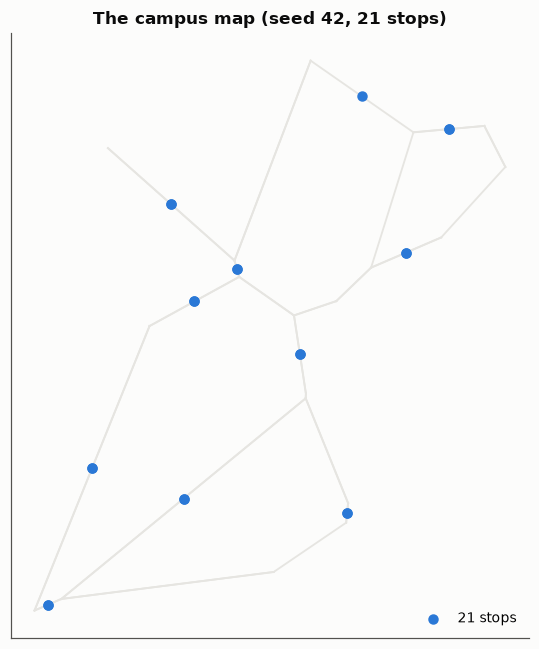

In [5]:
def draw_map(provider, title, ax=None, annotate=False):
    """
    Draw a map's roads and stops.
    :param provider: Any MapProvider.
    :param title: Title for the axes.
    :param ax: Axes to draw on; a new figure is made when None.
    :param annotate: Label each stop with its ID.
    :return: The axes drawn on.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(6.4, 6.0))
    nodes = {n.id: (n.x, n.y) for n in provider.get_road_nodes()}
    for edge in provider.get_road_edges():
        if edge.from_node_id in nodes and edge.to_node_id in nodes:
            (x0, y0), (x1, y1) = nodes[edge.from_node_id], nodes[edge.to_node_id]
            ax.plot([x0, x1], [y0, y1], color=GRID, lw=1.2, zorder=1)
    stops = provider.get_stops()
    ax.scatter([s.x for s in stops], [s.y for s in stops], s=34,
               color=SERIES[0], zorder=3, label=f"{len(stops)} stops")
    if annotate:
        for stop in stops:
            # The short authored ID, not the transit-graph node ID: the node
            # IDs are long enough that 25 of them collide into illegibility.
            ax.annotate(stop.name or stop.id, (stop.x, stop.y), fontsize=7,
                        color=INK, xytext=(4, 4),
                        textcoords="offset points")
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.legend(loc="lower right")
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


draw_map(campus, "The campus map (seed 42, 21 stops)")
plt.tight_layout()

### A trap worth knowing about

`stop_density` defaults to `0.15`. On this seed that gives **six** stops — a
map so small that there is barely a routing decision to make, every policy
serves nearly everyone, and every comparison collapses into noise.

This is not hypothetical: a result in this project was once reported as "did
not reproduce" because it had been re-measured on the six-stop version. The
`0.5` above is load-bearing, which is why it is stated with every figure.

In [6]:
for density in (0.15, 0.5):
    small = PlanarMapProvider(
        PlanarStreetGraph.generate(**{**CAMPUS, "stop_density": density}))
    print(f"stop_density={density}: {len(small.get_stops()):>2} stops")

stop_density=0.15:  6 stops
stop_density=0.5: 21 stops


## 3. What routing on it costs

`TransitGraph` answers two questions for the policies: what is the best path
between two pieces of road, and what does it cost. **Cost is travel time, not
distance** — every edge is priced by its length and the road's speed limit,
so a longer fast road beats a shorter slow one.

The travel times are asymmetric, because one-way streets mean the way back is
not the way there.

In [7]:
stops = campus_graph.get_stops()
a, b = stops[0].edge.id, stops[7].edge.id

print(f"path from {a} to {b}:")
for node in campus_graph.best_path(a, b):
    print(f"   {node}")
print(f"\ncost there: {campus_graph.best_path_cost(a, b):>7.1f} s")
print(f"cost back:  {campus_graph.best_path_cost(b, a):>7.1f} s")

costs = [campus_graph.best_path_cost(s.edge.id, t.edge.id)
         for s in stops for t in stops if s is not t]
print(f"\ntypical hop between two stops: {sorted(costs)[len(costs) // 2]:.0f} s")

path from 0_1 to 6_5:
   0_1
   1_8
   8_6
   6_5

cost there:   143.0 s
cost back:    150.9 s

typical hop between two stops: 132 s


That median hop is the number the policies scale their defaults
off: a service window given as "5x the typical hop" means five times this.

## 4. The real worlds: CARLA towns

The same `MapProvider` interface is implemented by `CarlaMapProvider`, which
reads two files per town:

- a **topology dump** — every road, its length and its speed limit, extracted
  from a running CARLA server once (`src/preparation/carla_dump.py`) and
  committed;
- a **hand-authored stop list** — where the bus stops are, which is a human
  decision nothing can make for us.

Because both are files, a CARLA town can be routed, plotted and reasoned
about **with no server running**. Only actually driving it needs CARLA.

In [8]:
import pandas as pd
from tqdm.auto import tqdm

from src.map.CarlaMapProvider import CarlaMapProvider

TOWNS = ["Town01", "Town02", "Town03", "Town05", "TAU"]

rows = []
# Loading a town parses its whole road dump; TAU alone is 560 segments.
for town in tqdm(TOWNS, desc="loading towns", unit="town"):
    provider = CarlaMapProvider(town)
    rows.append({
        "town": town,
        "stops": len(provider.get_stops()),
        "road segments": len(provider.get_road_edges()),
        "lane changes": len(provider.get_lane_changes()),
        "traffic_efficiency": round(provider.traffic_efficiency(), 4),
        "problems": len(provider.validate()),
    })

display(pd.DataFrame(rows).set_index("town"))

loading towns:   0%|          | 0/5 [00:00<?, ?town/s]

,stops,road segments,lane changes,traffic_efficiency,problems
town,,,,,
Town01,15,139,0,0.4751,0
Town02,15,103,0,0.4645,0
Town03,15,423,210,0.5980,3
Town05,15,497,342,0.3309,0
TAU,25,560,122,0.7032,34


`traffic_efficiency` is the fraction of the free-flow travel
time the bus actually achieves in that town, **measured by driving it** — see
notebook 07. A town at 0.35 means the bus takes nearly three times as long as
the speed limits alone would suggest, mostly waiting at red lights.

`problems` counts stops the map could not place or reach; the campaign prunes
those before running.

drawing:   0%|          | 0/3 [00:00<?, ?town/s]

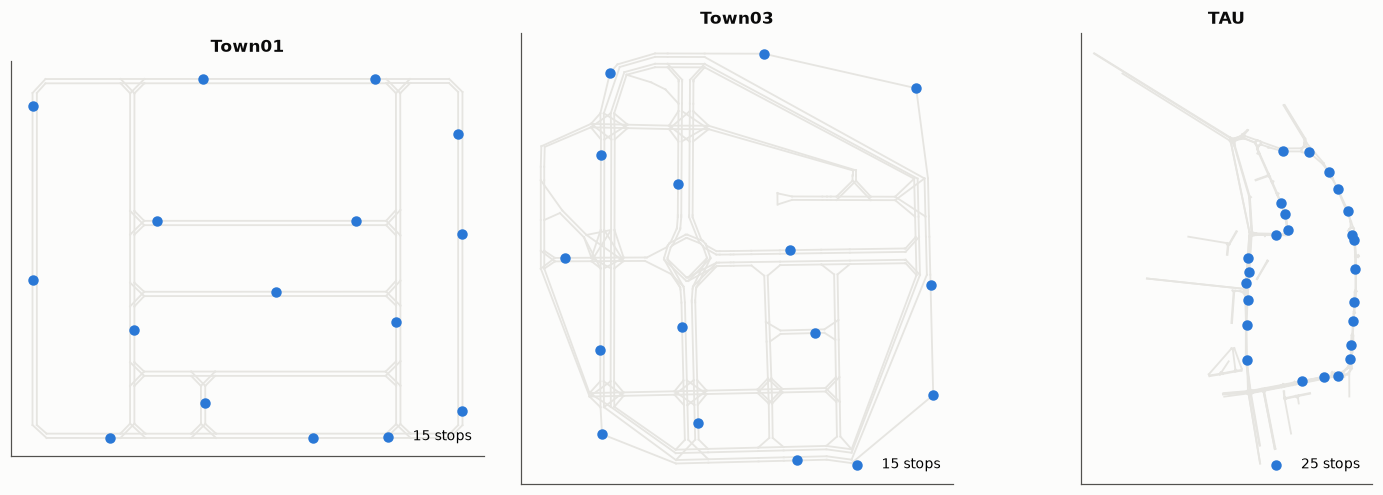

In [9]:
figure, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
for axis, town in zip(axes, tqdm(["Town01", "Town03", "TAU"],
                                 desc="drawing", unit="town")):
    draw_map(CarlaMapProvider(town), town, ax=axis)
figure.tight_layout()

## 5. TAU — a real place

`TAU` above is not a CARLA town. It is **Tel Aviv University**, built from
OpenStreetMap data: the campus's real roads converted to a CARLA-drivable map,
with 25 stops placed by hand at real buildings, dorms and gates.

It went beyond what the project needed, and it is the strongest demonstration
that the pipeline is not tied to the four towns CARLA ships. Its stops are
named after the places they serve.

  s00   שער 5 - יוסף קריס
  s01   שער 1 - אוסטריה
  s02   שער 16 - עבודה סוציאלית
  s03   שער 8 - דן בוכנר
  s04   שער 4 - רמנסיאנו
  s05   שער 3
  s06   G5
  s07   שער 9 - יוסף סאפר
  ... 25 stops in total


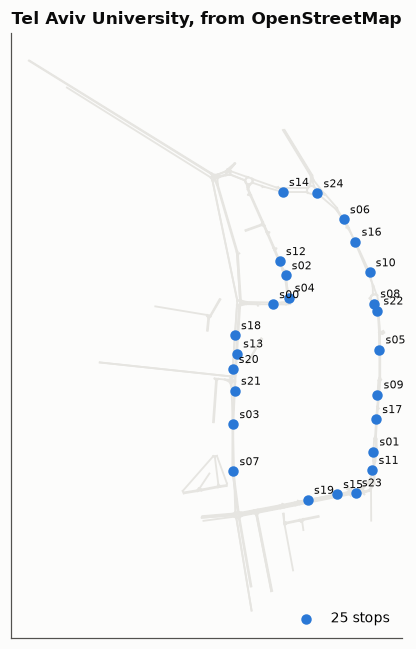

In [10]:
from src.map.carla_stops import load_stops

tau = CarlaMapProvider("TAU")

# The authored file carries the human-readable names; the routing layer only
# ever needs the IDs, so StopRecord keeps the ID and drops the label.
for stop in load_stops("TAU")[:8]:
    print("  {:<5} {}".format(stop.id, stop.name or ""))
print(f"  ... {len(tau.get_stops())} stops in total")

draw_map(tau, "Tel Aviv University, from OpenStreetMap", annotate=True)
plt.tight_layout()

## What to take from this

- **One interface, four worlds.** A hand-authored test map, a generated
  planar map, four CARLA towns and a real campus all arrive as a
  `MapProvider`, and nothing above that layer knows which it is holding.
- **Roads are nodes.** That inversion is what lets a bus stop be a place the
  bus can be routed *to*, and it makes turn restrictions structural rather
  than a rule to enforce.
- **Cost is time.** Everything downstream — every policy, every KPI — is
  denominated in seconds.

Next: **02 — Demand and KPIs**, which is where the passengers come from.